# Gestenerkennung mit neuronalem Netz


In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, os
import tensorflow as tf
from tensorflow.keras import Sequential, layers, optimizers, losses, metrics
from sklearn.model_selection import train_test_split
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, roc_auc_score
from tqdm.keras import TqdmCallback

## 1. Daten laden & vorbereiten


In [2]:
def process_gesture_data(csv_path, label):
    samples, gestures, current = [], [], []
    gesture, blank_run = 0, 0
    with open(csv_path) as f:
        for line in f:
            line = line.strip()
            if not line:
                if current: samples.append(current); gestures.append(gesture); current = []
                blank_run += 1
                if blank_run == 2: gesture += 1      
            else:
                current.append(list(map(float, line.split(","))))
                blank_run = 0
    if current: samples.append(current); gestures.append(gesture)
    X = np.array([np.array(s) for s in samples], dtype=np.float32)
    return X, np.full(len(X), label, dtype=np.float32), np.array(gestures)

lbl_punch, lbl_lift = 0, 1
Xp, yp, gp = process_gesture_data("data/punch.csv", lbl_punch)
Xl, yl, gl = process_gesture_data("data/lift.csv",  lbl_lift)
X = np.concatenate([Xp, Xl]); y = np.concatenate([yp, yl])
g = np.concatenate([gp, gl + gp.max() + 1])          # Gesten-IDs über alle Klassen eindeutig
print("X:", X.shape, "y:", y.shape, "Gesten:", len(np.unique(g)))

X: (2010, 119, 6) y: (2010,) Gesten: 201


### Normalisierung

In [3]:
X_mean = X.mean(axis=(0, 1))
X_std  = X.std(axis=(0, 1))
X_norm = (X - X_mean) / X_std
print("mean:", np.round(X_mean, 3))
print("std :", np.round(X_std, 3))
c_floats = lambda v: ", ".join(f"{x:.3f}f" for x in v)
print(f"const float kMean[kChannels] = {{{c_floats(X_mean)}}};")
print(f"const float kStd[kChannels]  = {{{c_floats(X_std)}}};")

mean: [-0.026 -0.025  0.978  1.76   0.888  1.212]
std : [ 0.177  0.174  0.234 27.099 26.389 28.157]
const float kMean[kChannels] = {-0.026f, -0.025f, 0.978f, 1.760f, 0.888f, 1.212f};
const float kStd[kChannels]  = {0.177f, 0.174f, 0.234f, 27.099f, 26.389f, 28.157f};


### Datensatz visualisieren (PCA)

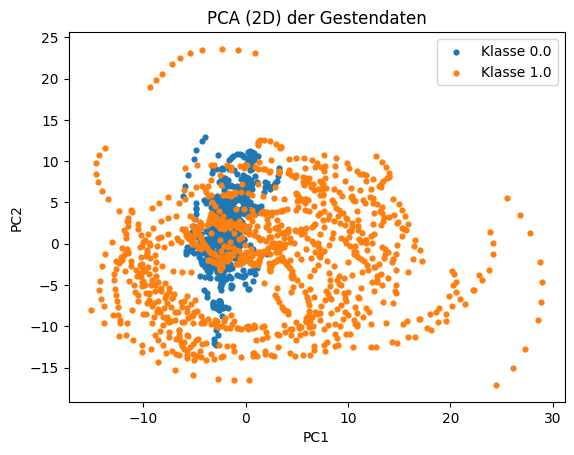

In [4]:
from sklearn.decomposition import PCA
Xf = X_norm.reshape(len(X_norm), -1)            # Fenster zu Vektoren flach ziehen
proj = PCA(n_components=2).fit_transform(Xf)
for c in np.unique(y):
    m = (y == c)
    plt.scatter(proj[m, 0], proj[m, 1], s=12, label=f"Klasse {c}")
plt.legend(); plt.xlabel("PC1"); plt.ylabel("PC2")
plt.title("PCA (2D) der Gestendaten"); plt.show()

In [5]:
from sklearn.model_selection import StratifiedGroupKFold
train_idx, test_idx = next(StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=42).split(X_norm, y, g))
X_train, X_test, y_train, y_test = X_norm[train_idx], X_norm[test_idx], y[train_idx], y[test_idx]
print("Train:", X_train.shape[0], "Test:", X_test.shape[0],
      "| Gesten Train/Test:", len(np.unique(g[train_idx])), "/", len(np.unique(g[test_idx])),
      "| gemeinsame Gesten:", len(np.intersect1d(g[train_idx], g[test_idx])))

Train: 1340 Test: 670 | Gesten Train/Test: 134 / 67 | gemeinsame Gesten: 0


## 2. Modell definieren 


In [39]:
# TODO: Sequential-Modell aufbauen (siehe Beschreibung oben)
model = Sequential([
    layers.Input((119, 6)),
    layers.Flatten(),
    layers.Dense(18, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(6, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])
model.summary()

Model: "sequential_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┓
┃ Layer (type)                ┃ Output Shape        ┃     Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━┩
│ flatten_9 (Flatten)         │ (None, 714)         │           0 │
├─────────────────────────────┼─────────────────────┼─────────────┤
│ dense_27 (Dense)            │ (None, 18)          │      12,870 │
├─────────────────────────────┼─────────────────────┼─────────────┤
│ dropout_9 (Dropout)         │ (None, 18)          │           0 │
├─────────────────────────────┼─────────────────────┼─────────────┤
│ dense_28 (Dense)            │ (None, 6)           │         114 │
├─────────────────────────────┼─────────────────────┼─────────────┤
│ dense_29 (Dense)            │ (None, 1)           │           7 │
└─────────────────────────────┴─────────────────────┴─────────────┘

 Total params: 12,991 (50.75 KB)

 Trainable params: 12,991 (50.75 KB)

 Non-trainable params: 0 (0.00 B)

## 3. Kompilieren & trainieren  

In [40]:
optimizer = optimizers.Adam(learning_rate=1e-3)
loss_fn = losses.BinaryCrossentropy()

model.compile(loss=loss_fn, optimizer=optimizer,
              metrics=[metrics.BinaryAccuracy(name="accuracy"), metrics.Precision(name="precision"),
                       metrics.Recall(name="recall"), metrics.AUC(name="auc")])
history = model.fit(X_train, y_train, validation_data=(X_test, y_test), epochs=10, batch_size=16,
                    verbose=0, callbacks=[TqdmCallback(verbose=0)])


0epoch [00:00, ?epoch/s]

## 4. Evaluation

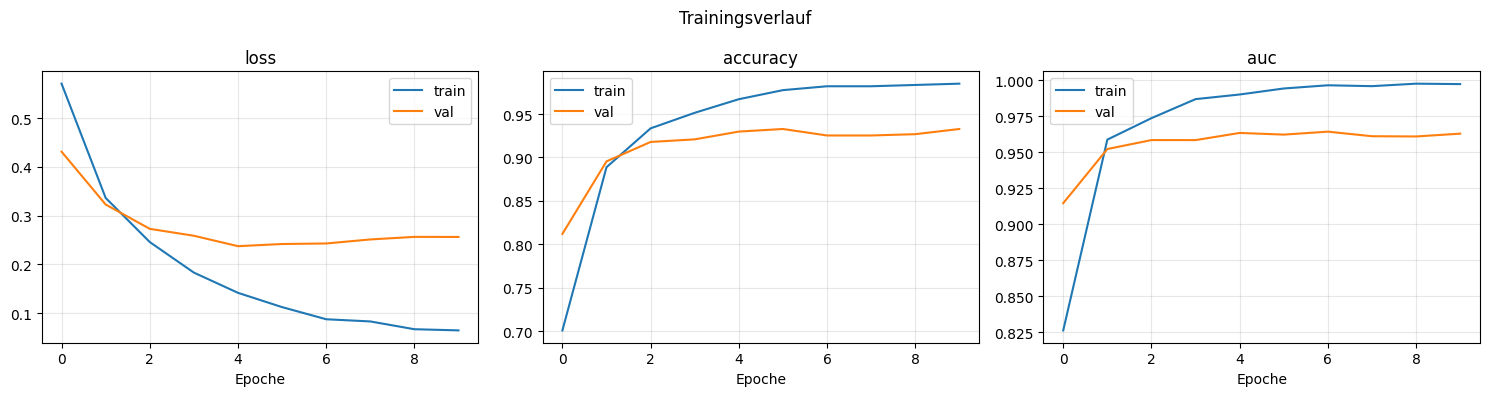

=== Keras-Modell (float) ===
Accuracy: 93.3%   ROC-AUC: 0.967
Board (Margin 0.15): unsicher 1.8%, Accuracy der Entscheidungen 93.5%
              precision    recall  f1-score   support

       Punch      0.946     0.921     0.933       340
        Lift      0.920     0.945     0.933       330

    accuracy                          0.933       670
   macro avg      0.933     0.933     0.933       670
weighted avg      0.933     0.933     0.933       670



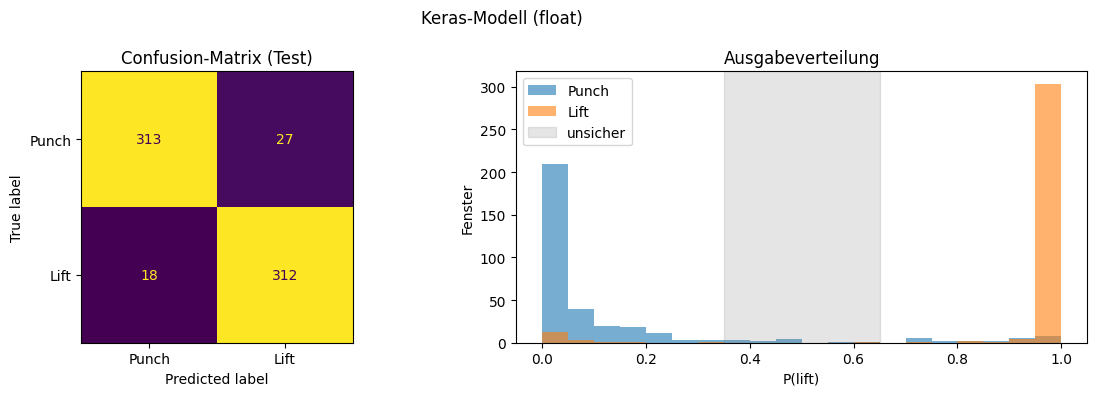

In [41]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, key in zip(axes, ["loss", "accuracy", "auc"]):
    ax.plot(history.history[key], label="train")
    ax.plot(history.history["val_" + key], label="val")
    ax.set_xlabel("Epoche"); ax.set_title(key); ax.legend(); ax.grid(alpha=0.3)
fig.suptitle("Trainingsverlauf"); plt.tight_layout(); plt.show()

# Wie kDecisionMargin in tflite.ino: näher als dieser Abstand an 0.5 zeigt das Board "unsicher"
DECISION_MARGIN = 0.15
CLASS_NAMES = ["Punch", "Lift"]

def report(p_lift, y_true, title):
    """Metriken für P(lift)-Vorhersagen — für das Keras-Modell und das int8-Modell gleichermaßen."""
    y_true = y_true.astype(int)
    y_pred = (p_lift > 0.5).astype(int)
    decided = np.abs(p_lift - 0.5) >= DECISION_MARGIN
    print(f"=== {title} ===")
    print(f"Accuracy: {np.mean(y_pred == y_true)*100:.1f}%   ROC-AUC: {roc_auc_score(y_true, p_lift):.3f}")
    print(f"Board (Margin {DECISION_MARGIN}): unsicher {np.mean(~decided)*100:.1f}%, "
          f"Accuracy der Entscheidungen {np.mean(y_pred[decided] == y_true[decided])*100:.1f}%")
    print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=3))

    fig, (ax_cm, ax_hist) = plt.subplots(1, 2, figsize=(12, 4))
    ConfusionMatrixDisplay.from_predictions(y_true, y_pred, display_labels=CLASS_NAMES, ax=ax_cm, colorbar=False)
    ax_cm.set_title("Confusion-Matrix (Test)")
    # Verteilung der Ausgaben: gute Modelle drücken die Klassen an 0 bzw. 1, nicht um 0.5
    for c, name in enumerate(CLASS_NAMES):
        ax_hist.hist(p_lift[y_true == c], bins=20, range=(0, 1), alpha=0.6, label=name)
    ax_hist.axvspan(0.5 - DECISION_MARGIN, 0.5 + DECISION_MARGIN, color="grey", alpha=0.2, label="unsicher")
    ax_hist.set_xlabel("P(lift)"); ax_hist.set_ylabel("Fenster"); ax_hist.legend(); ax_hist.set_title("Ausgabeverteilung")
    fig.suptitle(title); plt.tight_layout(); plt.show()

report(model.predict(X_test, verbose=0).ravel(), y_test, "Keras-Modell (float)")

## 5. Konvertieren nach TensorFlow Lite 

INFO:tensorflow:Assets written to: C:\Users\leofe\AppData\Local\Temp\tmp66qfnfog\assets


INFO:tensorflow:Assets written to: C:\Users\leofe\AppData\Local\Temp\tmp66qfnfog\assets


Saved artifact at 'C:\Users\leofe\AppData\Local\Temp\tmp66qfnfog'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 119, 6), dtype=tf.float32, name='keras_tensor_54')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  1604141103056: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1602301542672: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1602301544208: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1602301551312: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1602301549776: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1602301554384: TensorSpec(shape=(), dtype=tf.resource, name=None)


C:\Users\leofe\AppData\Local\Programs\Python\Python312\Lib\site-packages\tensorflow\lite\python\convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
C:\Users\leofe\AppData\Local\Programs\Python\Python312\Lib\site-packages\tensorflow\lite\python\interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


Das TFLite-Modell wurde erfolgreich als 'tflite/gesture_nn.tflite' gespeichert.
Modellgröße: 17.20 KB
=== TFLite-Modell (int8, läuft auf dem Board) ===
Accuracy: 92.8%   ROC-AUC: 0.964
Board (Margin 0.15): unsicher 1.8%, Accuracy der Entscheidungen 93.2%
              precision    recall  f1-score   support

       Punch      0.945     0.912     0.928       340
        Lift      0.912     0.945     0.929       330

    accuracy                          0.928       670
   macro avg      0.929     0.929     0.928       670
weighted avg      0.929     0.928     0.928       670



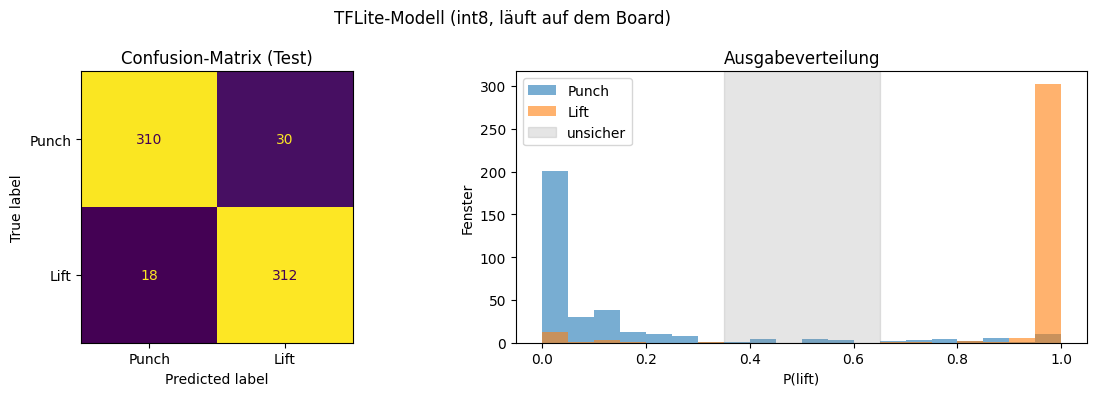

In [42]:
converter = tf.lite.TFLiteConverter.from_keras_model(model)

converter.optimizations = [tf.lite.Optimize.DEFAULT]
def representative_data():
    for i in range(len(X_train)):
        yield [X_train[i:i+1]]
converter.representative_dataset = representative_data
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]

tflite_model = converter.convert()

filename = 'tflite/gesture_nn.tflite'
with open(filename, 'wb') as f:
    f.write(tflite_model)

file_size_bytes = os.path.getsize(filename)
file_size_kb = file_size_bytes / 1024

print(f"Das TFLite-Modell wurde erfolgreich als '{filename}' gespeichert.")
print(f"Modellgröße: {file_size_kb:.2f} KB")

interpreter = tf.lite.Interpreter(model_content=tflite_model)
interpreter.allocate_tensors()
inp, out = interpreter.get_input_details()[0], interpreter.get_output_details()[0]
tfl_pred = []
for x in X_test:
    interpreter.set_tensor(inp["index"], x[None].astype(np.float32))
    interpreter.invoke()
    tfl_pred.append(interpreter.get_tensor(out["index"])[0, 0])
report(np.array(tfl_pred), y_test, "TFLite-Modell (int8, läuft auf dem Board)")

## 6. Export als C-Array (`model.h`)

In [43]:
with open('tflite/gesture_nn.tflite', 'rb') as f:
    tflite_binary = f.read()

hex_lines = []
for i, byte in enumerate(tflite_binary):
    if i % 12 == 0:
        hex_lines.append("\n  ")
    hex_lines.append(f"0x{byte:02x}, ")

c_array_content = "".join(hex_lines).rstrip(", ")

with open('tflite/model.h', 'w') as f:
    f.write("alignas(16) const unsigned char model[] = {")
    f.write(c_array_content)
    f.write("\n};\n")
    # Optional: 
    f.write(f"const unsigned int model_len = {len(tflite_binary)};\n")

print("model.h:", round(os.path.getsize("tflite/model.h")/1024, 2), "KB")

model.h: 109.04 KB
